In [1]:
# 1. 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')            # 드라이브를 /content/drive 에 연결

Mounted at /content/drive


In [2]:
# 2. 라이브러리 불러오기 (PyTorch, 이미지 도구)
import os                                # 파일·폴더 다루는 도구
import torch                             # PyTorch 본체: 텐서 계산, 신경망 학습
import torchvision                       # 이미지 데이터셋, 유명 모델 제공
import torchvision.transforms as transforms   # 이미지 전처리 도구
import pandas as pd                      # 표(CSV) 다루는 도구

In [3]:
# 3. 라벨 파일(CSV) 확인
df = pd.read_csv('/content/drive/MyDrive/pokedex-samples/train.csv')   # 전체 경로로 읽기
print(df.columns)                        # 열 이름: id(파일 이름), label(정답)
print(df.head())                         # 위에서 5줄
print(len(df))                           # 전체 사진 수 (5243)

Index(['id', 'label'], dtype='object')
         id       label
0  44263a6b     Scyther
1  9b6344f2  Butterfree
2  c89ffbde      Rhydon
3  95bbd7ff     Koffing
4  c3e8a9e1     Dewgong
5243


In [4]:
# 4. 사진 압축 풀기 (드라이브 → Colab 작업 공간)
!unzip -q -o '/content/drive/MyDrive/pokedex-samples/train.zip' -d /content/data
print(len(os.listdir('/content/data/train')))   # 5243이면 성공

5243


In [5]:
# 5. 사진을 라벨(포켓몬 이름)별 폴더로 정리
import shutil                            # 파일 복사 도구

img_dir = '/content/data/train'          # 원본 사진 폴더
out_dir = '/content/sorted'              # 정리된 폴더

missing = 0
for _, row in df.iterrows():             # CSV 한 줄씩
    fname = str(row['id']) + '.jpg'      # 파일 이름 (확장자 붙이기)
    label = str(row['label'])            # 정답 = 폴더 이름
    os.makedirs(os.path.join(out_dir, label), exist_ok=True)
    src = os.path.join(img_dir, fname)
    if os.path.exists(src):
        shutil.copy(src, os.path.join(out_dir, label, fname))
    else:
        missing += 1

print('정리 끝, 없는 파일 수:', missing)                  # 0이면 성공
print('클래스 폴더 수:', len(os.listdir(out_dir)))        # 150이면 성공

정리 끝, 없는 파일 수: 0
클래스 폴더 수: 150


In [6]:
# 이미지 파일의 크기 확인

from PIL import Image

sizes = set()                            # 중복 없이 크기 종류만 모으기
for f in os.listdir('/content/data/train'):
    with Image.open(os.path.join('/content/data/train', f)) as img:
        sizes.add(img.size)

print(sizes)                             # 나온 크기 종류 전부 출력

{(224, 224)}


In [30]:
# 6. 데이터 준비 (수동 실험용)
torch.manual_seed(42)                    # 랜덤 고정: 실행할 때마다 같은 방식으로 데이터를 나누기

transform = transforms.Compose(          # 전처리 단계들을 순서대로 묶기
    [transforms.ToTensor(),              # 사진 → 숫자 텐서로 변환 (0~1 값)
     # transforms.Resize((128,128)),     # 축소 실험용: 224 → 128 (빠름, 디테일 손실) / 7번 fc1도 같이 바꾸기
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])  # RGB 각 채널 값을 -1~1 범위로 정규화

batch_size = 32                          # 한 번에 학습할 사진 묶음 크기

trainset = torchvision.datasets.ImageFolder(root='/content/sorted', transform=transform)  # CSV 라벨대로 정리한 폴더 이름을 정답으로 삼아 사진 불러오기
classes = trainset.classes               # 클래스(포켓몬 이름) 목록 저장
print('클래스 수:', len(classes), '/ 전체 사진:', len(trainset))  # 150 / 5243이면 정상

n_train = int(len(trainset) * 0.8)       # 학습용 사진 수 = 전체의 80%
trainset, testset = torch.utils.data.random_split(trainset, [n_train, len(trainset) - n_train])  # 학습용 / 테스트용 무작위 분할

trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)   # 학습 데이터를 배치 단위로 꺼내기 (매번 섞음)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)    # 테스트 데이터용 (섞지 않음)

클래스 수: 150 / 전체 사진: 5243


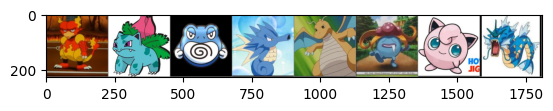

Magmar Ivysaur Poliwrath Seadra Dragonite Gloom Jigglypuff Gyarados


In [35]:
# 6-1. 데이터 확인 (사진과 라벨이 맞는지 눈으로 보기)
import matplotlib.pyplot as plt          # 그래프·이미지 그리는 도구
import numpy as np                       # 숫자 배열 계산 도구

def imshow(img):                         # 텐서 이미지를 화면에 보여주는 함수
    img = img / 2 + 0.5                  # 정규화(-1~1)를 되돌려 0~1로
    npimg = img.numpy()                  # 텐서 → numpy 배열
    plt.imshow(np.transpose(npimg, (1, 2, 0)))  # (채널, 세로, 가로) → (세로, 가로, 채널) 순서로 바꿔 그리기
    plt.show()

dataiter = iter(trainloader)             # 학습 데이터에서 배치 꺼낼 준비
images, labels = next(dataiter)          # 배치 하나(32장) 꺼내기

imshow(torchvision.utils.make_grid(images[:8]))              # 앞의 8장만 격자로 보여주기
print(' / '.join(classes[labels[j]] for j in range(8)))      # 8장의 정답 라벨 출력

In [31]:
# 클래스 이름 확인

print(classes)

['Abra', 'Aerodactyl', 'Alakazam', 'Alolan Sandslash', 'Arbok', 'Arcanine', 'Articuno', 'Beedrill', 'Bellsprout', 'Blastoise', 'Bulbasaur', 'Butterfree', 'Caterpie', 'Chansey', 'Charizard', 'Charmander', 'Charmeleon', 'Clefable', 'Clefairy', 'Cloyster', 'Cubone', 'Dewgong', 'Diglett', 'Ditto', 'Dodrio', 'Doduo', 'Dragonair', 'Dragonite', 'Dratini', 'Drowzee', 'Dugtrio', 'Eevee', 'Ekans', 'Electabuzz', 'Electrode', 'Exeggcute', 'Exeggutor', 'Farfetchd', 'Fearow', 'Flareon', 'Gastly', 'Gengar', 'Geodude', 'Gloom', 'Golbat', 'Goldeen', 'Golduck', 'Golem', 'Graveler', 'Grimer', 'Growlithe', 'Gyarados', 'Haunter', 'Hitmonchan', 'Hitmonlee', 'Horsea', 'Hypno', 'Ivysaur', 'Jigglypuff', 'Jolteon', 'Jynx', 'Kabuto', 'Kabutops', 'Kadabra', 'Kakuna', 'Kangaskhan', 'Kingler', 'Koffing', 'Krabby', 'Lapras', 'Lickitung', 'Machamp', 'Machoke', 'Machop', 'Magikarp', 'Magmar', 'Magnemite', 'Magneton', 'Mankey', 'Marowak', 'Meowth', 'Metapod', 'Mew', 'Mewtwo', 'Moltres', 'MrMime', 'Muk', 'Nidoking', 'Ni

In [32]:
# 훈련세팅과 시험세팅 갯수 확인

print(len(trainset))
print(len(testset))

4194
1049


In [51]:
# 7~9번 셀은 수동 실험용 학습으로 작성한 것

# 7. 모델 구조 정의 (CNN 3층, 수동 실험용)
import torch.nn as nn                    # 신경망 층(conv, linear 등) 모음
import torch.nn.functional as F          # 활성화 함수(relu 등) 모음

device = 'cuda' if torch.cuda.is_available() else 'cpu'     # GPU 있으면 GPU 사용
print('사용 장치:', device)              # cuda가 나와야 빠름

class Net(nn.Module):                    # CNN 모델 설계도
    def __init__(self):
        super().__init__()                           # 신경망 모델로 등록 (필수)
        self.conv1 = nn.Conv2d(3, 6, 5)              # 합성곱1: (입력 채널 3, 필터 6개, 커널 5×5)
        self.conv2 = nn.Conv2d(6, 16, 5)             # 합성곱2: (입력 6, 필터 16개, 커널 5×5)
        self.conv3 = nn.Conv2d(16, 32, 5)            # 합성곱3: (입력 16, 필터 32개, 커널 5×5)
        self.pool = nn.MaxPool2d(2, 2)               # 풀링: 2×2 중 최대값만 남겨 크기 절반
        self.fc1 = nn.Linear(32*24*24, 120)          # 224 기준: 224→110→53→24 / 128이면 32*12*12
        self.fc2 = nn.Linear(120, 84)                # 은닉층: 120 → 84
        self.fc3 = nn.Linear(84, len(classes))       # 출력층: 클래스 수(150)만큼

    def forward(self, x):                # 데이터가 흘러가는 순서
        x = self.pool(F.relu(self.conv1(x)))         # 224 → 220 → 110
        x = self.pool(F.relu(self.conv2(x)))         # 110 → 106 → 53
        x = self.pool(F.relu(self.conv3(x)))         # 53 → 49 → 24
        x = torch.flatten(x, 1)                      # 특징 지도를 1줄로 펼치기
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)                              # 최종 점수 (클래스별)
        return x

net = Net().to(device)                   # 모델 만들고 GPU로 옮기기

사용 장치: cpu


In [52]:
# 8. 손실 함수와 옵티마이저 설정 (7번 다음에 반드시 실행)
import torch.optim as optim              # 옵티마이저 모음

criterion = nn.CrossEntropyLoss()                                   # 분류용 손실 함수
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)     # 옵티마이저, 학습률, 모멘텀
# optimizer = optim.Adam(net.parameters(), lr=0.001)                # 실험용: Adam

In [53]:
# 9. 정확도 함수 + 학습
import time

def test_accuracy():                     # 테스트 정확도 계산 함수
    net.eval()                           # 평가 모드로 전환
    correct, total = 0, 0                # 맞힌 개수, 전체 개수
    with torch.no_grad():                # 평가할 땐 기울기 계산 안 함 → 빠르고 메모리 절약
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)   # GPU로 옮기기
            _, predicted = torch.max(net(images), 1)  # 150개 점수 중 가장 높은 클래스 고르기
            total += labels.size(0)                   # 전체 개수 증가
            correct += (predicted == labels).sum().item()   # 맞힌 개수 더하기
    net.train()                          # 다시 학습 모드로
    return 100 * correct / total         # 정답률 %

epochs = 5                               # 실험 하나당 5 에포크
test_every_epoch = True                  # True: 매 에포크 테스트 / False: 마지막에만 테스트 (시간 절약)

train_time = 0.0                         # 순수 학습 시간 합계
test_time = 0.0                          # 테스트 시간 합계

for epoch in range(epochs):              # 에포크 수만큼 반복
    t0 = time.time()                     # 이번 에포크 학습 시작 시각
    running_loss = 0.0                   # 이번 에포크 loss 합계
    for inputs, labels in trainloader:   # 학습 데이터를 배치 단위로 꺼내기
        inputs, labels = inputs.to(device), labels.to(device)   # 데이터를 GPU로
        optimizer.zero_grad()            # 이전 기울기 초기화
        outputs = net(inputs)            # 순전파: 예측
        loss = criterion(outputs, labels)  # 오차 계산
        loss.backward()                  # 역전파: 기울기 계산
        optimizer.step()                 # 가중치 수정
        running_loss += loss.item()      # loss 합계에 더하기
    train_time += time.time() - t0       # 이번 에포크 학습 시간 더하기

    avg_loss = running_loss / len(trainloader)   # 평균 loss
    if test_every_epoch or epoch == epochs - 1:  # 매번 테스트하거나, 마지막 에포크일 때만
        t1 = time.time()
        acc = test_accuracy()
        test_time += time.time() - t1    # 테스트 시간 더하기
        print(f'[{epoch + 1}] loss: {avg_loss:.3f} / 테스트 정확도: {acc:.1f}%')
    else:
        print(f'[{epoch + 1}] loss: {avg_loss:.3f}')

print(f'학습 시간: {train_time:.1f}초 / 테스트 시간: {test_time:.1f}초')

[1] loss: 5.012 / 테스트 정확도: 0.7%
[2] loss: 5.011 / 테스트 정확도: 0.7%
[3] loss: 5.010 / 테스트 정확도: 0.7%
[4] loss: 5.011 / 테스트 정확도: 0.7%
[5] loss: 5.009 / 테스트 정확도: 0.7%
학습 시간: 588.9초 / 테스트 시간: 74.1초


10~12번 셀은 자동 실험용 학습임

In [16]:
# 10. 자동 실험: 설정값으로 모델 만들기 (fc1 자동 계산 + Dropout + BatchNorm)
import torch.nn as nn                    # 신경망 층 모음
import torch.nn.functional as F          # 활성화 함수 모음
import torch.optim as optim              # 옵티마이저 모음

device = 'cuda' if torch.cuda.is_available() else 'cpu'   # GPU 있으면 GPU 사용
print('사용 장치:', device)              # cuda가 나와야 빠름

class FlexNet(nn.Module):                # 층 수, 이미지 크기, Dropout, BatchNorm을 받아서 만드는 CNN
    def __init__(self, n_layers, img_size, n_classes, dropout=0.0, bn=False):
        super().__init__()                           # 신경망 모델로 등록 (필수)
        filters = [6, 16, 32, 64][:n_layers]         # 층별 필터 개수 (2층: 6,16 / 4층: 6,16,32,64)
        in_ch = 3                                    # 첫 입력은 RGB 3채널
        self.convs = nn.ModuleList()                 # conv 층 목록
        self.bns = nn.ModuleList()                   # BatchNorm 층 목록
        for out_ch in filters:
            self.convs.append(nn.Conv2d(in_ch, out_ch, 5))                     # 합성곱 층 (커널 5×5)
            self.bns.append(nn.BatchNorm2d(out_ch) if bn else nn.Identity())   # bn=False면 아무것도 안 하는 층
            in_ch = out_ch                           # 다음 층 입력 = 이번 층 출력
        self.pool = nn.MaxPool2d(2, 2)               # 풀링: 크기 절반

        with torch.no_grad():                        # fc1 크기 자동 계산
            dummy = torch.zeros(1, 3, img_size, img_size)    # 가짜 사진 한 장
            self.eval()                              # BatchNorm이 사진 1장으로도 계산되게 평가 모드
            flat_size = self._features(dummy).shape[1]       # conv 통과 후 펼친 길이
            self.train()                             # 다시 학습 모드

        self.fc1 = nn.Linear(flat_size, 120)         # 자동 계산된 크기 사용
        self.drop = nn.Dropout(dropout)              # Dropout (0이면 끔)
        self.fc2 = nn.Linear(120, 84)                # 은닉층
        self.fc3 = nn.Linear(84, n_classes)          # 출력층: 클래스 수(150)

    def _features(self, x):                          # conv → BatchNorm → relu → pool 반복 후 펼치기
        for conv, bn in zip(self.convs, self.bns):
            x = self.pool(F.relu(bn(conv(x))))
        return torch.flatten(x, 1)

    def forward(self, x):                            # 데이터가 흘러가는 순서
        x = self._features(x)
        x = self.drop(F.relu(self.fc1(x)))           # fc1 → relu → Dropout
        x = F.relu(self.fc2(x))
        return self.fc3(x)                           # 클래스별 점수

사용 장치: cuda


In [17]:
# 11. 자동 실험: 데이터 로더 + 실험 함수 (증강 강도 선택 + 노이즈)
import time

class AddNoise:                                      # 사진에 가우시안 노이즈(잡티) 섞기
    def __init__(self, std=0.05):
        self.std = std                               # 노이즈 세기 (0~1 범위 기준 5%)
    def __call__(self, x):
        return (x + torch.randn_like(x) * self.std).clamp(0, 1)   # 노이즈 더하고 0~1 범위로 자르기

def make_loaders(img_size, batch_size, aug='none', workers=2):
    resize_norm = [transforms.Resize((img_size, img_size)),                    # 실험할 크기로
                   transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]     # -1~1로 정규화

    if aug == 'basic':                               # 기본 증강 (지난 실험과 동일)
        train_list = [transforms.RandomHorizontalFlip(),                       # 좌우 뒤집기
                      transforms.RandomRotation(10),                           # -10~10도 회전
                      transforms.ToTensor()] + resize_norm
    elif aug == 'strong':                            # 강한 증강
        train_list = [transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),    # 80~100% 영역을 잘라 확대
                      transforms.RandomHorizontalFlip(),                       # 좌우 뒤집기
                      transforms.RandomRotation(15),                           # -15~15도 회전
                      transforms.ColorJitter(brightness=0.2, contrast=0.2),    # 밝기·대비만 변화 (색상은 그대로)
                      transforms.ToTensor(),                                   # 사진 → 텐서
                      AddNoise(0.05)] + resize_norm                           # 노이즈 추가
    else:                                            # 증강 없음
        train_list = [transforms.ToTensor()] + resize_norm

    train_tf = transforms.Compose(train_list)                                  # 학습용 전처리
    test_tf = transforms.Compose([transforms.ToTensor()] + resize_norm)        # 테스트용: 항상 증강 없이

    train_full = torchvision.datasets.ImageFolder(root='/content/sorted', transform=train_tf)
    test_full = torchvision.datasets.ImageFolder(root='/content/sorted', transform=test_tf)

    n = len(train_full)
    n_train = int(n * 0.8)                           # 학습 80%
    idx = torch.randperm(n, generator=torch.Generator().manual_seed(42)).tolist()   # 분할은 항상 같게
    tr = torch.utils.data.Subset(train_full, idx[:n_train])    # 학습 사진 → 증강 적용
    te = torch.utils.data.Subset(test_full, idx[n_train:])     # 테스트 사진 → 증강 없음

    trl = torch.utils.data.DataLoader(tr, batch_size=batch_size, shuffle=True, num_workers=workers)
    tel = torch.utils.data.DataLoader(te, batch_size=batch_size, shuffle=False, num_workers=workers)
    return trl, tel, len(train_full.classes)

def run_experiment(cfg):                             # 설정 하나로 학습 → 결과 반환
    torch.manual_seed(cfg['seed'])                   # 시드: 모델 초기값, 학습 순서
    trl, tel, n_classes = make_loaders(cfg['img'], cfg['batch'], cfg['aug'], cfg['workers'])
    net = FlexNet(cfg['layers'], cfg['img'], n_classes, cfg['dropout'], cfg['bn']).to(device)
    criterion = nn.CrossEntropyLoss()                # 분류용 손실 함수
    if cfg['opt'] == 'SGD':
        optimizer = optim.SGD(net.parameters(), lr=cfg['lr'], momentum=0.9)
    else:
        optimizer = optim.Adam(net.parameters(), lr=cfg['lr'])

    net.train()                                      # 학습 모드 (Dropout, BatchNorm 학습 동작 켜짐)
    t0 = time.time()
    for epoch in range(cfg['epochs']):
        running_loss = 0.0
        for inputs, labels in trl:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()                    # 기울기 초기화
            loss = criterion(net(inputs), labels)    # 예측 + 오차 계산
            loss.backward()                          # 기울기 계산
            optimizer.step()                         # 가중치 수정
            running_loss += loss.item()
        print(f'  [{epoch + 1}] loss: {running_loss / len(trl):.3f}')
    train_time = time.time() - t0                    # 순수 학습 시간

    net.eval()                                       # 평가 모드 (Dropout 끄기, BatchNorm 고정)
    t1 = time.time()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in tel:
            images, labels = images.to(device), labels.to(device)
            _, pred = torch.max(net(images), 1)      # 가장 점수 높은 클래스
            total += labels.size(0)
            correct += (pred == labels).sum().item()
    test_time = time.time() - t1                     # 테스트 시간

    params = sum(p.numel() for p in net.parameters())    # 모델 크기
    return {**cfg,
            'loss': round(running_loss / len(trl), 3),
            'acc': round(100 * correct / total, 1),
            'train_time': round(train_time, 1),
            'test_time': round(test_time, 1),
            'params': params}

In [19]:
# 12. 자동 실험: 증강 강도 × 에포크 → BatchNorm + 기록 저장 + 최종 결과 정리
from datetime import datetime
from zoneinfo import ZoneInfo
from google.colab import files

RUN_ID = datetime.now(ZoneInfo('Asia/Seoul')).strftime('%Y%m%d_%H%M%S')   # 실험 시작 시각
print('실험 ID:', RUN_ID)

# True: 1 에포크, 첫 단계만 (에러 확인용) / False: 본 실험
#QUICK = True
QUICK = False

SAVE_DIR = '/content/drive/MyDrive/pokedex-samples'
LOG = f'{SAVE_DIR}/experiment_log_{RUN_ID}.csv'          # 실험 중 기록
RESULT = f'{SAVE_DIR}/experiment_result_{RUN_ID}.csv'    # 최종 정리 결과

results = []
done = {}

def run_and_log(cfg):                    # 실험 하나 실행 + 기록
    key = tuple(sorted(cfg.items()))
    if key in done:                      # 같은 설정이면 재사용
        return done[key]
    print('실험 시작:', cfg)
    r = run_experiment(cfg)
    print(f"→ 정확도 {r['acc']}% / 학습 {r['train_time']}초 / 테스트 {r['test_time']}초\n")
    done[key] = r
    results.append(r)
    pd.DataFrame(results).to_csv(LOG, index=False)
    return r

def pick_best(rs):                       # 정확도 최고, 같으면 학습 시간 짧은 쪽
    return sorted(rs, key=lambda r: (-r['acc'], r['train_time']))[0]

# 지난 실험의 최적 설정에서 출발 (2층, 기본 증강, Dropout 없음)
best = dict(layers=2, img=224, batch=16, opt='Adam', lr=0.0001, epochs=10,
            dropout=0.0, aug='basic', seed=42, workers=2, bn=False)

if QUICK:
    # 시험: 기본/강한 증강을 1 에포크씩 → 에러 확인 + 1 에포크 시간 측정
    stages = [('증강 강도 (시험)', [dict(aug=a, epochs=1) for a in ['basic', 'strong']])]
else:
    stages = [
        # ----- 1. 증강 강도 × 에포크: 오래 배우면 강한 증강이 역전하나? -----
        ('증강 강도 × 에포크', [dict(aug=a, epochs=e) for e in [10, 20] for a in ['basic', 'strong']]),
        # ----- 2. BatchNorm: 학습을 빠르고 안정적으로 만드나? -----
        ('BatchNorm',         [dict(bn=b) for b in [False, True]]),
    ]

for name, options in stages:
    print(f'===== {name} 단계 =====')
    rs = [run_and_log({**best, **opt}) for opt in options]
    b = pick_best(rs)
    best = {k: b[k] for k in best}       # 최고 설정을 다음 단계 기준으로
    print(f'>>> {name} 최적: {best}\n')

print('최종 최적 설정:', best)

# ----- 최종 결과 정리 -----
df_result = pd.DataFrame(results)
df_result = df_result.sort_values(['acc', 'train_time'], ascending=[False, True])
df_result = df_result.rename(columns={
    'layers': '층 수', 'img': '이미지 크기', 'batch': '배치', 'opt': '옵티마이저',
    'lr': '학습률', 'epochs': '에포크', 'dropout': 'Dropout', 'aug': '데이터 증강',
    'seed': '시드', 'workers': 'num_workers', 'bn': 'BatchNorm',
    'loss': '마지막 loss', 'acc': '테스트 정확도(%)',
    'train_time': '학습 시간(초)', 'test_time': '테스트 시간(초)', 'params': '파라미터 수'})

df_result.to_csv(RESULT, index=False, encoding='utf-8-sig')
print('저장 완료:', RESULT)
files.download(RESULT)
df_result

실험 ID: 20261016_142441
===== 증강 강도 × 에포크 단계 =====
실험 시작: {'layers': 2, 'img': 224, 'batch': 16, 'opt': 'Adam', 'lr': 0.0001, 'epochs': 10, 'dropout': 0.0, 'aug': 'basic', 'seed': 42, 'workers': 2, 'bn': False}
  [1] loss: 5.008
  [2] loss: 4.794
  [3] loss: 4.156
  [4] loss: 3.594
  [5] loss: 3.268
  [6] loss: 3.050
  [7] loss: 2.856
  [8] loss: 2.730
  [9] loss: 2.634
  [10] loss: 2.544
→ 정확도 24.2% / 학습 81.9초 / 테스트 1.7초

실험 시작: {'layers': 2, 'img': 224, 'batch': 16, 'opt': 'Adam', 'lr': 0.0001, 'epochs': 10, 'dropout': 0.0, 'aug': 'strong', 'seed': 42, 'workers': 2, 'bn': False}
  [1] loss: 5.004
  [2] loss: 4.767
  [3] loss: 4.200
  [4] loss: 3.739
  [5] loss: 3.460
  [6] loss: 3.298
  [7] loss: 3.148
  [8] loss: 3.034
  [9] loss: 2.935
  [10] loss: 2.858
→ 정확도 25.5% / 학습 201.2초 / 테스트 1.7초

실험 시작: {'layers': 2, 'img': 224, 'batch': 16, 'opt': 'Adam', 'lr': 0.0001, 'epochs': 20, 'dropout': 0.0, 'aug': 'basic', 'seed': 42, 'workers': 2, 'bn': False}
  [1] loss: 5.008
  [2] loss: 4.783


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,층 수,이미지 크기,배치,옵티마이저,학습률,에포크,Dropout,데이터 증강,시드,num_workers,BatchNorm,마지막 loss,테스트 정확도(%),학습 시간(초),테스트 시간(초),파라미터 수
2,2,224,16,Adam,0.0001,20,0.0,basic,42,2,False,1.699,35.7,160.3,1.6,5419186
4,2,224,16,Adam,0.0001,20,0.0,basic,42,2,True,2.197,32.4,160.8,1.6,5419230
3,2,224,16,Adam,0.0001,20,0.0,strong,42,2,False,2.326,32.0,400.8,1.7,5419186
1,2,224,16,Adam,0.0001,10,0.0,strong,42,2,False,2.858,25.5,201.2,1.7,5419186
0,2,224,16,Adam,0.0001,10,0.0,basic,42,2,False,2.544,24.2,81.9,1.7,5419186


## 최종 최적 조건

3차례 자동 실험 결과 정리

| 항목 | 최종 값 | 근거 |
|---|---|---|
| 층 수 | 2층 | 시드 3개 평균 26.3%로 가장 높고 가장 안정적 |
| 이미지 크기 | 224 | 128과 비슷, 64는 크게 하락 / 128이 빠르지도 않음 |
| 배치 | 16 | 1차 실험 최고 |
| 옵티마이저 | Adam 0.0001 | SGD는 10 에포크에도 거의 못 배움 |
| 데이터 증강 | 기본 (뒤집기 + 10° 회전) | 강한 증강은 정확도 낮고 2.5배 느림 |
| Dropout / BatchNorm | 없음 | 둘 다 이 조건에서 이득 없음 |
| 에포크 | 20 | 10 → 20에서 +11.5%p, 가장 큰 개선 |
| **결과** | **35.7%** | 찍기(0.67%) 대비 약 53배 |

In [20]:
# 13. 최종 최적 조건으로 학습 (10, 11번 셀의 FlexNet, make_loaders 사용)
FINAL = dict(layers=2, img=224, batch=16, opt='Adam', lr=0.0001, epochs=20,
             dropout=0.0, aug='basic', seed=42, workers=2, bn=False)   # 3차 실험 최적 설정
print('최종 설정:', FINAL)

torch.manual_seed(FINAL['seed'])
trainloader, testloader, n_classes = make_loaders(FINAL['img'], FINAL['batch'], FINAL['aug'], FINAL['workers'])
classes = torchvision.datasets.ImageFolder(root='/content/sorted').classes   # 포켓몬 이름 목록 (14번 예측 확인용)

net = FlexNet(FINAL['layers'], FINAL['img'], n_classes, FINAL['dropout'], FINAL['bn']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(net.parameters(), lr=FINAL['lr'])
print('파라미터 수:', sum(p.numel() for p in net.parameters()))   # 5,419,186이면 실험 때와 같은 모델

def test_accuracy():                     # 테스트 정확도 계산
    net.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            _, predicted = torch.max(net(images), 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    net.train()
    return 100 * correct / total

history = []                             # 에포크별 기록 (학습 곡선용)
train_time = 0.0
net.train()
for epoch in range(FINAL['epochs']):
    t0 = time.time()
    running_loss = 0.0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()            # 기울기 초기화
        loss = criterion(net(inputs), labels)   # 예측 + 오차 계산
        loss.backward()                  # 기울기 계산
        optimizer.step()                 # 가중치 수정
        running_loss += loss.item()
    train_time += time.time() - t0
    acc = test_accuracy()                # 매 에포크 테스트 정확도
    history.append(dict(epoch=epoch + 1, loss=round(running_loss / len(trainloader), 3), acc=round(acc, 1)))
    print(f"[{epoch + 1:2d}] loss: {history[-1]['loss']:.3f} / 테스트 정확도: {acc:.1f}%")

print(f'학습 시간: {train_time:.1f}초 / 최종 정확도: {history[-1]["acc"]}%')

FINAL_ID = datetime.now(ZoneInfo('Asia/Seoul')).strftime('%Y%m%d_%H%M%S')
pd.DataFrame(history).to_csv(f'{SAVE_DIR}/final_history_{FINAL_ID}.csv', index=False, encoding='utf-8-sig')   # 에포크별 기록 저장

최종 설정: {'layers': 2, 'img': 224, 'batch': 16, 'opt': 'Adam', 'lr': 0.0001, 'epochs': 20, 'dropout': 0.0, 'aug': 'basic', 'seed': 42, 'workers': 2, 'bn': False}
파라미터 수: 5419186
[ 1] loss: 5.007 / 테스트 정확도: 1.3%
[ 2] loss: 4.755 / 테스트 정확도: 6.1%
[ 3] loss: 4.067 / 테스트 정확도: 10.0%
[ 4] loss: 3.497 / 테스트 정확도: 16.1%
[ 5] loss: 3.172 / 테스트 정확도: 18.6%
[ 6] loss: 2.952 / 테스트 정확도: 22.3%
[ 7] loss: 2.780 / 테스트 정확도: 23.7%
[ 8] loss: 2.630 / 테스트 정확도: 23.9%
[ 9] loss: 2.500 / 테스트 정확도: 26.2%
[10] loss: 2.393 / 테스트 정확도: 26.5%
[11] loss: 2.292 / 테스트 정확도: 29.0%
[12] loss: 2.201 / 테스트 정확도: 28.5%
[13] loss: 2.114 / 테스트 정확도: 31.5%
[14] loss: 2.030 / 테스트 정확도: 30.3%
[15] loss: 1.956 / 테스트 정확도: 31.9%
[16] loss: 1.884 / 테스트 정확도: 30.3%
[17] loss: 1.826 / 테스트 정확도: 32.0%
[18] loss: 1.755 / 테스트 정확도: 32.8%
[19] loss: 1.692 / 테스트 정확도: 33.8%
[20] loss: 1.634 / 테스트 정확도: 33.7%
학습 시간: 163.2초 / 최종 정확도: 33.7%


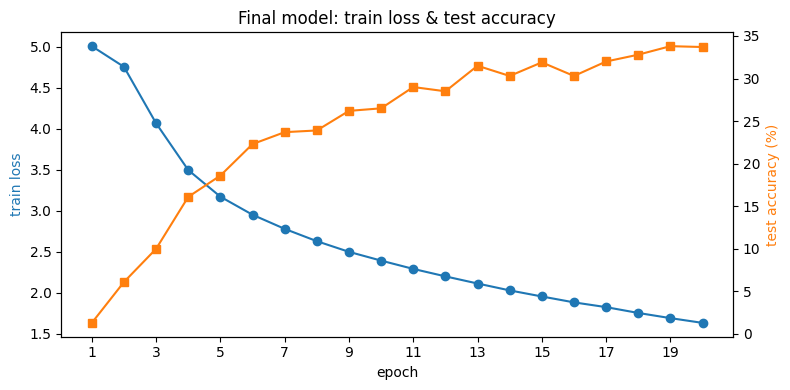

In [22]:
# 13-1. 최종 모델 학습 곡선 (리포트용)
import matplotlib.pyplot as plt

h = pd.DataFrame(history)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(h['epoch'], h['loss'], color='tab:blue', marker='o')        # 왼쪽 축: 학습 loss
ax1.set_xlabel('epoch')
ax1.set_xticks(range(1, len(h) + 1, 2))      # x축 눈금을 1, 3, 5... 정수로
ax1.set_ylabel('train loss', color='tab:blue')
ax2 = ax1.twinx()                                                    # 오른쪽 축: 테스트 정확도
ax2.plot(h['epoch'], h['acc'], color='tab:orange', marker='s')
ax2.set_ylabel('test accuracy (%)', color='tab:orange')
plt.title('Final model: train loss & test accuracy')
fig.tight_layout()
plt.savefig(f'{SAVE_DIR}/final_curve_{FINAL_ID}.png', dpi=150)       # 그래프 이미지 드라이브에 저장
plt.show()
# 정확도가 20 에포크까지 계속 오르면 → 에포크를 더 늘릴 여지가 있다는 뜻

In [23]:
# 14. 최종 모델 저장 (실험이 모두 끝난 뒤, 가장 좋은 모델만 저장)

PATH = '/content/drive/MyDrive/pokedex-samples/pokemon_cnn_3layer.pth'   # 저장 위치 (드라이브라서 런타임이 꺼져도 유지됨)
torch.save(net.state_dict(), PATH)       # 모델이 학습한 가중치를 파일로 저장 (게임 세이브 파일 같은 것)

In [ ]:
# 14-1. 저장한 모델 불러오기 (다시 학습하지 않고 바로 사용)

net = Net().to(device)                   # 같은 구조의 빈 모델 만들기
net.load_state_dict(torch.load(PATH))    # 저장한 가중치 채워 넣기

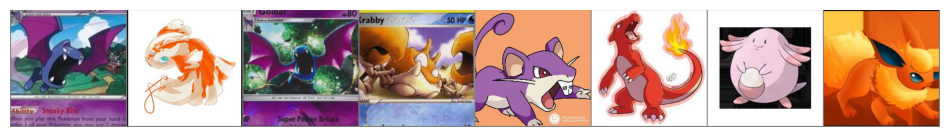

1. 정답: Golbat       예측: Zubat        X
2. 정답: Goldeen      예측: Spearow      X
3. 정답: Golbat       예측: Zubat        X
4. 정답: Krabby       예측: Kingler      X
5. 정답: Rattata      예측: Rattata      O
6. 정답: Charmeleon   예측: Charmeleon   O
7. 정답: Chansey      예측: MrMime       X
8. 정답: Flareon      예측: Moltres      X


In [25]:
# 15. 예측 결과 눈으로 확인 (리포트용)
import numpy as np                       # 숫자 배열 계산 도구
import matplotlib.pyplot as plt          # 그래프·이미지 그리는 도구

def imshow(img):                         # 텐서 이미지를 화면에 보여주는 함수
    img = img / 2 + 0.5                  # 정규화(-1~1)를 되돌려 0~1로
    plt.figure(figsize=(12, 3))          # 8장이 잘 보이게 가로로 넓게
    plt.imshow(np.transpose(img.numpy(), (1, 2, 0)))  # (채널, 세로, 가로) → (세로, 가로, 채널)
    plt.axis('off')                      # 축 눈금 숨기기
    plt.show()

dataiter = iter(testloader)              # 테스트 데이터에서 배치 꺼낼 준비
images, labels = next(dataiter)          # 배치 하나(16장) 꺼내기
images, labels = images[:8], labels[:8]  # 앞의 8장만 사용

imshow(torchvision.utils.make_grid(images))   # 사진 8장을 격자로 보여주기

net.eval()                               # 평가 모드
with torch.no_grad():                    # 예측만 하고 학습은 안 함
    _, predicted = torch.max(net(images.to(device)), 1)   # 가장 점수 높은 클래스 고르기

for j in range(8):                       # 한 장씩 정답과 예측 비교
    mark = 'O' if predicted[j].item() == labels[j].item() else 'X'
    print(f'{j + 1}. 정답: {classes[labels[j]]:<12} 예측: {classes[predicted[j]]:<12} {mark}')